# 01 · Exploratory Data Analysis

Goal: understand the weekly product panel before estimating any elasticity.

Questions:
1. What do prices and quantities look like?
2. Do prices actually change within a product? (Without price changes there is nothing to estimate.)
3. How strong is seasonality, and does price move with it? (If it does, season is a confounder.)
4. What does the raw price-demand relationship look like, and how does it change once we compare a product only with itself?

Data: `weekly_sales` table built by `python -m econocausal.data.build`.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from econocausal.data.db import load_panel, get_engine, read_table
from econocausal.viz import BLUE, ORANGE, GREY, TEXT_MUTED, save_figure, set_style

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

panel = load_panel().sort_values(["stock_code", "week_start"]).reset_index(drop=True)
panel.head()

,stock_code,week_start,description,price,quantity,revenue,n_invoices,n_customers,uk_share,guest_share,log_price,log_quantity,year,month,week_of_year,weeks_to_christmas,is_peak_season,has_bank_holiday,category
0,10002,2009-11-30,INFLATABLE POLITICAL GLOBE,0.850,140,119.000,10,10,0.800,0.000,-0.163,4.942,2009,11,49,3,1,0,other
1,10002,2009-12-07,INFLATABLE POLITICAL GLOBE,0.850,24,21.250,4,3,0.750,0.250,-0.163,3.178,2009,12,50,2,0,0,other
2,10002,2009-12-14,INFLATABLE POLITICAL GLOBE,0.850,37,32.300,3,2,1.000,0.333,-0.163,3.611,2009,12,51,1,0,0,other
3,10002,2009-12-21,INFLATABLE POLITICAL GLOBE,0.850,14,12.750,3,2,1.000,0.333,-0.163,2.639,2009,12,52,0,0,1,other
4,10002,2010-01-04,INFLATABLE POLITICAL GLOBE,0.850,15,12.750,2,2,1.000,0.000,-0.163,2.708,2010,1,1,50,0,0,other


## 1. Overview

In [2]:
overview = pd.Series({
    "rows (product-weeks)": len(panel),
    "products": panel["stock_code"].nunique(),
    "weeks": panel["week_start"].nunique(),
    "first week": panel["week_start"].min().date(),
    "last week": panel["week_start"].max().date(),
    "total units": panel["quantity"].sum(),
    "total revenue (GBP)": round(panel["revenue"].sum()),
})
overview.to_frame("value")

,value
rows (product-weeks),126672
products,1877
weeks,103
first week,2009-11-30
last week,2011-11-28
total units,5796333
total revenue (GBP),10346165


In [3]:
read_table("cleaning_log", get_engine())

,step,rows_removed,rows_left
0,drop_cancellations,19500,1047871
1,drop_non_positive,6202,1041669
2,keep_product_codes,4792,1036877
3,drop_duplicates,33663,1003214
4,drop_price_outliers,882,1002332
5,drop_bulk_outliers,101,1002231


## 2. Distributions of price and quantity

Both are strongly right-skewed: most products are cheap and sell a few units a week, a few sell
hundreds. On a log scale both look much closer to normal, which is one reason the demand model
uses `log(quantity)` and `log(price)`.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


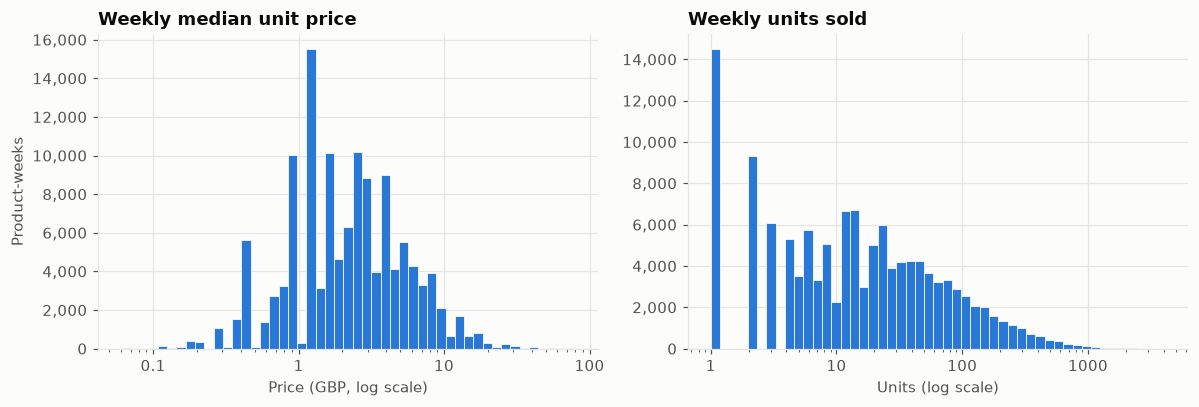

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

bins = np.logspace(np.log10(panel["price"].min()), np.log10(panel["price"].max()), 50)
axes[0].hist(panel["price"], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set_xscale("log")
axes[0].set_title("Weekly median unit price")
axes[0].set_xlabel("Price (GBP, log scale)")
axes[0].set_ylabel("Product-weeks")

bins = np.logspace(0, np.log10(panel["quantity"].max()), 50)
axes[1].hist(panel["quantity"], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set_xscale("log")
axes[1].set_title("Weekly units sold")
axes[1].set_xlabel("Units (log scale)")

for ax in axes:
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

fig.tight_layout()
save_figure(fig, "01_price_quantity_distributions")

In [5]:
panel[["price", "quantity", "revenue", "n_invoices", "n_customers"]].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95]
).T

,count,mean,std,min,25%,50%,75%,95%,max
price,"126,672.000",3.199,3.711,0.060,1.250,2.100,3.755,9.645,79.950
quantity,"126,672.000",45.759,107.139,1.000,4.000,13.000,42.000,193.000,"4,115.000"
revenue,"126,672.000",81.677,198.998,0.100,10.080,26.900,76.050,319.819,"9,461.550"
n_invoices,"126,672.000",4.610,5.223,1.000,1.000,3.000,6.000,14.000,101.000
n_customers,"126,672.000",3.321,4.225,0.000,1.000,2.000,4.000,11.000,90.000


## 3. Price variation within products

DML estimates the elasticity from how quantity responds when a product's own price changes.
So the important variation is **within** a product over time, not between cheap and expensive products.

In [6]:
by_product = panel.groupby("stock_code")
within_dev = panel["log_price"] - by_product["log_price"].transform("mean")

price_sd = by_product["log_price"].std()
changed = by_product["price"].diff().abs() > 0.005
has_previous = by_product["price"].diff().notna()

variation = pd.Series({
    "share of log-price variance that is within products": within_dev.var() / panel["log_price"].var(),
    "median within-product SD of log price": price_sd.median(),
    "products with SD of log price > 0.15": (price_sd > 0.15).mean(),
    "share of weeks where price changed vs previous sale week": changed[has_previous].mean(),
})
variation.to_frame("value")

,value
share of log-price variance that is within products,0.133
median within-product SD of log price,0.276
products with SD of log price > 0.15,0.902
share of weeks where price changed vs previous sale week,0.368


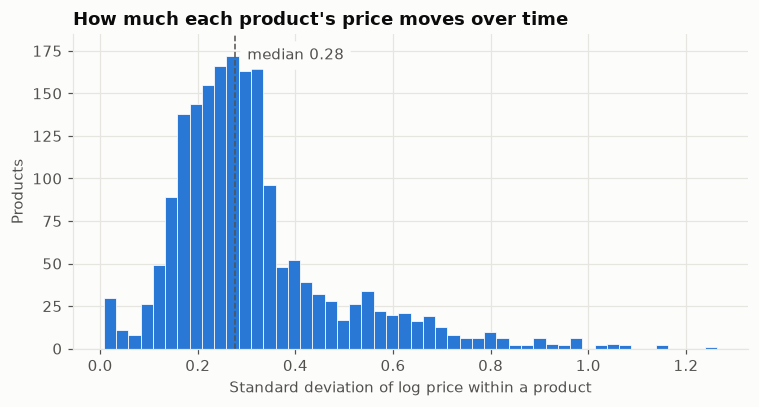

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(price_sd, bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(price_sd.median(), color=TEXT_MUTED, linewidth=1, linestyle="--")
ax.annotate(f"median {price_sd.median():.2f}", xy=(price_sd.median(), ax.get_ylim()[1] * 0.92),
            xytext=(8, 0), textcoords="offset points", color=TEXT_MUTED,
            backgroundcolor="#fcfcfb")
ax.set_title("How much each product's price moves over time")
ax.set_xlabel("Standard deviation of log price within a product")
ax.set_ylabel("Products")
fig.tight_layout()
save_figure(fig, "02_within_product_price_variation")

Price paths for four of the best-selling products. Prices move in steps (list price changes)
plus week-to-week noise from discounts and the mix of customers buying.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


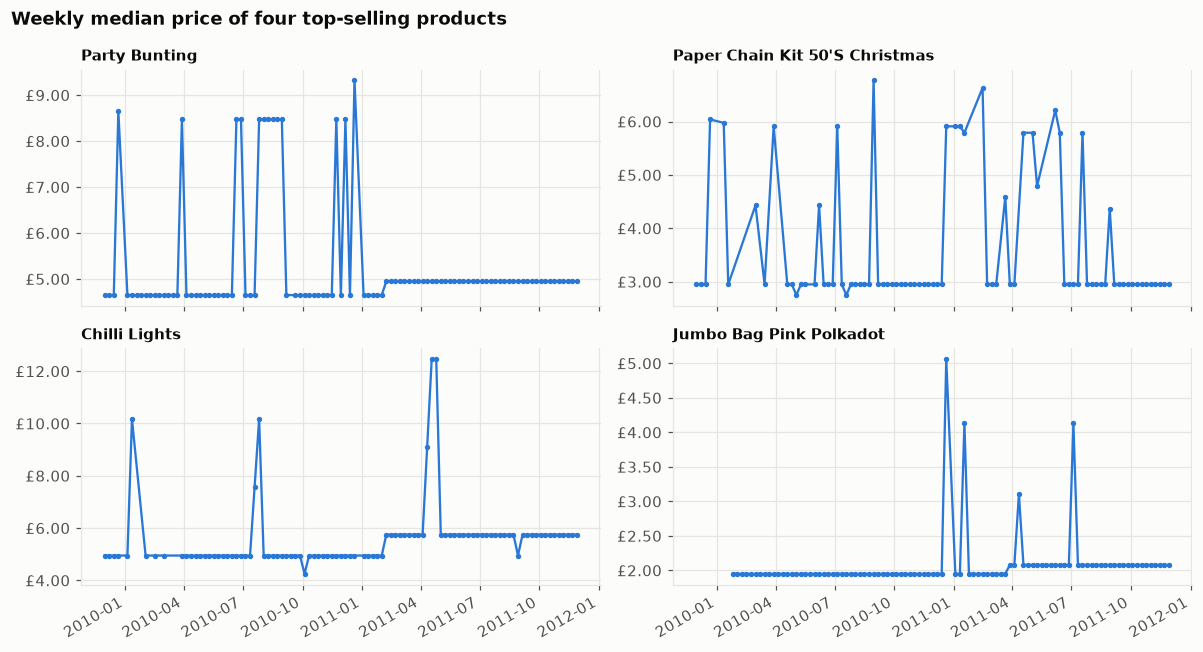

In [8]:
top = panel.groupby(["stock_code", "description"])["revenue"].sum().nlargest(4).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (_, row) in zip(axes.flat, top.iterrows()):
    d = panel[panel["stock_code"] == row["stock_code"]]
    ax.plot(d["week_start"], d["price"], color=BLUE, linewidth=1.5, marker="o", markersize=2.5)
    ax.set_title(row["description"].title(), fontsize=10)
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("£{x:.2f}"))
fig.suptitle("Weekly median price of four top-selling products", x=0.01, ha="left",
             fontweight="semibold")
fig.autofmt_xdate()
fig.tight_layout()
save_figure(fig, "03_example_price_paths")